## 1. stepup, device- agnostic:

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
from features import FEATURE_COLS   # the 23 model features

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")  # will print 'cpu' locally, 'cuda' automatically if you move this to Colab later

feature_df = pd.read_csv('../data/processed/feature_matrix.csv', parse_dates=['date'])


X = feature_df[FEATURE_COLS].values
y_home = feature_df['home_score'].values.astype(np.float32)
y_away = feature_df['away_score'].values.astype(np.float32)

from sklearn.model_selection import train_test_split
X_train_np, X_test_np, yh_train, yh_test, ya_train, ya_test = train_test_split(
    X, y_home, y_away, test_size=0.2, random_state=42
)

# Scale -- neural nets need this, unlike XGBoost
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_np)
X_test_scaled = scaler.transform(X_test_np)

class MatchDataset(Dataset):
    def __init__(self, X, y_home, y_away):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y_home = torch.tensor(y_home, dtype=torch.float32)
        self.y_away = torch.tensor(y_away, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y_home[idx], self.y_away[idx]

train_ds = MatchDataset(X_train_scaled, yh_train, ya_train)
test_ds = MatchDataset(X_test_scaled, yh_test, ya_test)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

class LambdaNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(32, 2), nn.Softplus()
        )
    def forward(self, x):
        out = self.net(x)
        return torch.clamp(out, min=0.2, max=5.0)

model = LambdaNet(input_dim=len(FEATURE_COLS)).to(device)
print(model)
print(f"\nTotal params: {sum(p.numel() for p in model.parameters())}")

Using device: cpu
LambdaNet(
  (net): Sequential(
    (0): Linear(in_features=23, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=2, bias=True)
    (7): Softplus(beta=1.0, threshold=20.0)
  )
)

Total params: 3682


## 2. training loop,early stopping mlflow:

Epoch 10: train=1.4350, val=1.4713
Early stopping at epoch 17


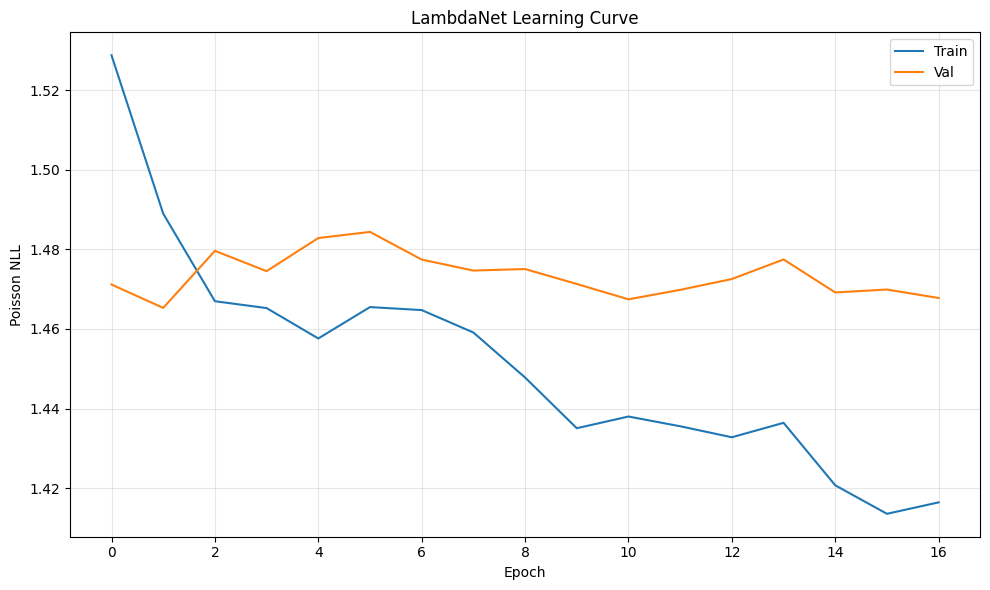


Best val loss: 1.4653


In [6]:
import torch.optim as optim
import matplotlib.pyplot as plt
import mlflow
import os
os.makedirs('../models', exist_ok=True)
os.makedirs('../visualization', exist_ok=True)

def poisson_nll(pred, target):
    lam = pred + 1e-8
    return (lam - target * torch.log(lam)).mean()

optimizer = optim.Adam(model.parameters(), lr=0.01)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

EPOCHS = 200
PATIENCE = 15
best_val_loss = float('inf')
patience_counter = 0
train_losses, val_losses = [], []

with mlflow.start_run(run_name='lambdanet_pytorch'):
    mlflow.log_params({'architecture': '14->64->32->2', 'dropout': 0.3, 'lr': 0.01,
                        'optimizer': 'Adam', 'loss': 'PoissonNLL', 'device': str(device),
                        'n_features': len(FEATURE_COLS)})

    for epoch in range(EPOCHS):
        model.train()
        epoch_train_loss = 0
        for xb, yh, ya in train_loader:
            xb, yh, ya = xb.to(device), yh.to(device), ya.to(device)
            optimizer.zero_grad()
            pred = model(xb)
            loss = poisson_nll(pred[:, 0], yh) + poisson_nll(pred[:, 1], ya)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item() * xb.size(0)
        epoch_train_loss /= len(train_ds)

        model.eval()
        epoch_val_loss = 0
        with torch.no_grad():
            for xb, yh, ya in test_loader:
                xb, yh, ya = xb.to(device), yh.to(device), ya.to(device)
                pred = model(xb)
                loss = poisson_nll(pred[:, 0], yh) + poisson_nll(pred[:, 1], ya)
                epoch_val_loss += loss.item() * xb.size(0)
        epoch_val_loss /= len(test_ds)

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)
        scheduler.step(epoch_val_loss)
        mlflow.log_metric('train_loss', epoch_train_loss, step=epoch)
        mlflow.log_metric('val_loss', epoch_val_loss, step=epoch)

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            patience_counter = 0
            torch.save(model.state_dict(), '../models/best_lambda_model.pth')
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f"Early stopping at epoch {epoch+1}")
                break

        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1}: train={epoch_train_loss:.4f}, val={epoch_val_loss:.4f}")

    mlflow.log_metric('best_val_loss', best_val_loss)
    mlflow.log_artifact('../models/best_lambda_model.pth')

    plt.figure(figsize=(10,6))
    plt.plot(train_losses, label='Train')
    plt.plot(val_losses, label='Val')
    plt.xlabel('Epoch'); plt.ylabel('Poisson NLL'); plt.title('LambdaNet Learning Curve')
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig('../visualization/learning_curve_lambdanet.png', dpi=150)
    mlflow.log_artifact('../visualization/learning_curve_lambdanet.png')
    plt.show()

print(f"\nBest val loss: {best_val_loss:.4f}")

In [7]:
model.eval()
with torch.no_grad():
    test_preds = model(torch.tensor(X_test_scaled, dtype=torch.float32).to(device)).cpu().numpy()

pred_lambda_home = test_preds[:, 0]
pred_lambda_away = test_preds[:, 1]

print(f"Actual avg home goals   : {yh_test.mean():.4f}   Predicted avg λ_home: {pred_lambda_home.mean():.4f}")
print(f"Actual avg away goals   : {ya_test.mean():.4f}   Predicted avg λ_away: {pred_lambda_away.mean():.4f}")
print(f"Home λ deviation        : {abs(pred_lambda_home.mean() - yh_test.mean()) / yh_test.mean() * 100:.2f}%")
print(f"Away λ deviation        : {abs(pred_lambda_away.mean() - ya_test.mean()) / ya_test.mean() * 100:.2f}%")

Actual avg home goals   : 1.6473   Predicted avg λ_home: 1.5978
Actual avg away goals   : 1.0835   Predicted avg λ_away: 1.1245
Home λ deviation        : 3.00%
Away λ deviation        : 3.78%


In [8]:
import joblib
joblib.dump(scaler, '../models/scaler.pkl')
print("✅ Saved")

✅ Saved
